# Judy's scratch: EDA on the raw data

Distributions from the **raw** data (`RAW_interactions.csv`, `RAW_recipes.csv`): ratings, and cooking time, steps and ingredients per recipe.

`rating = 0` means a review left without stars (every interaction is a written review; the star rating is optional).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../dataset/"
plt.rcParams.update({"figure.figsize": (6, 3.5), "axes.grid": True, "grid.alpha": 0.3})

inter = pd.read_csv(DATA_PATH + "RAW_interactions.csv")
recipes = pd.read_csv(DATA_PATH + "RAW_recipes.csv")
print(f"interactions {len(inter):,} | recipes {len(recipes):,}")

interactions 1,132,367 | recipes 231,637


## Distributions
- **Ratings:** all interactions, including rating 0.
- **Minutes:** the x-axis is log-scaled (each tick is a much bigger jump than the last) because of extreme outliers, up to about 4,000 years; ticks are labelled in plain time units. Recipes with 0 minutes can't appear on a log axis, so they're counted below instead.
- **Steps:** every value shown (the long tail out to 145 steps is too small to see as bars; see the printed counts).
- **Ingredients:** every value shown.

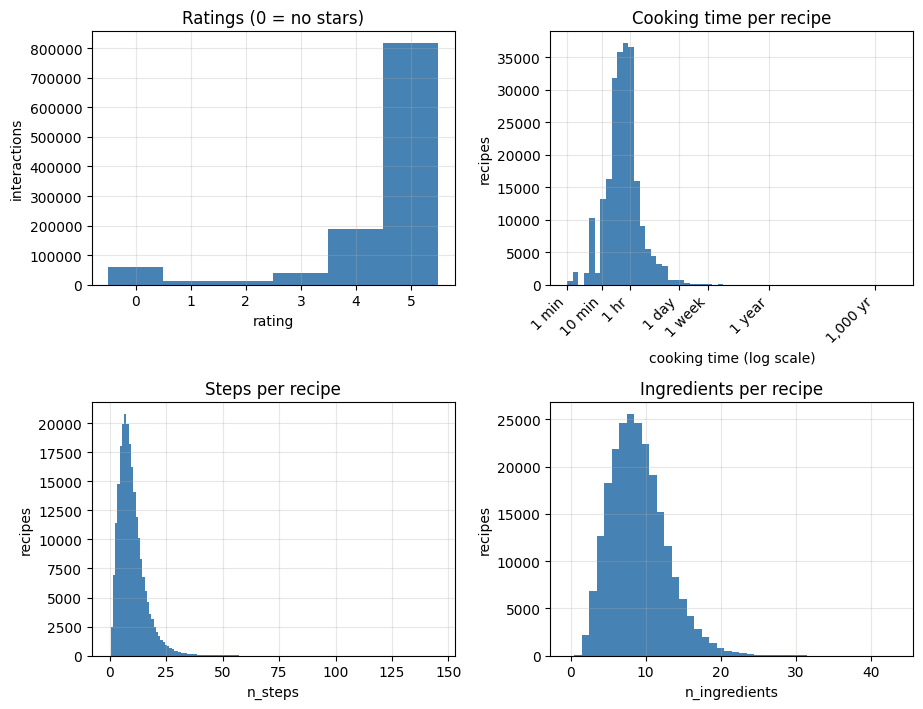

rating shares: 0: 5.4% | 1: 1.1% | 2: 1.2% | 3: 3.6% | 4: 16.5% | 5: 72.1%
minutes: min 0 | 1% 2 | median 40 | 99% 904 | max 2,147,483,647
n_steps: min 0 | 1% 1 | median 9 | 99% 30 | max 145
n_ingredients: min 1 | 1% 3 | median 9 | 99% 20 | max 43
minutes == 0: 1,094 | > 1 day: 2,000 | > 1 year: 2
n_steps == 0: 1 | 40+ steps: 628


In [2]:
fig, ax = plt.subplots(2, 2, figsize=(14 / 3 * 2, 3.6 * 2))

vals, cnts = np.unique(inter.rating, return_counts=True)
ax[0, 0].bar(vals, cnts, width=1, color="steelblue")
ax[0, 0].set_title("Ratings (0 = no stars)"); ax[0, 0].set_xlabel("rating"); ax[0, 0].set_ylabel("interactions")

mins = recipes.minutes.to_numpy()
pos = mins[mins > 0]
ax[0, 1].hist(pos, bins=np.logspace(0, np.log10(pos.max()), 60), color="steelblue")
ax[0, 1].set_xscale("log")
ticks = {1: "1 min", 10: "10 min", 60: "1 hr", 1440: "1 day", 10080: "1 week", 525600: "1 year", 525600000: "1,000 yr"}
ax[0, 1].set_xticks(list(ticks), list(ticks.values()), rotation=45, ha="right")
ax[0, 1].minorticks_off()
ax[0, 1].set_title("Cooking time per recipe"); ax[0, 1].set_xlabel("cooking time (log scale)"); ax[0, 1].set_ylabel("recipes")

ns = recipes.n_steps.to_numpy()
ax[1, 0].bar(np.arange(ns.max() + 1), np.bincount(ns), width=1, color="steelblue")
ax[1, 0].set_title("Steps per recipe"); ax[1, 0].set_xlabel("n_steps"); ax[1, 0].set_ylabel("recipes")

ni = recipes.n_ingredients.to_numpy()
ax[1, 1].bar(np.arange(ni.max() + 1), np.bincount(ni), width=1, color="steelblue")
ax[1, 1].set_title("Ingredients per recipe"); ax[1, 1].set_xlabel("n_ingredients"); ax[1, 1].set_ylabel("recipes")
plt.tight_layout(); plt.show()

print("rating shares: " + " | ".join(f"{v}: {c / cnts.sum():.1%}" for v, c in zip(vals, cnts)))
for name, v in [("minutes", mins), ("n_steps", ns), ("n_ingredients", ni)]:
    p1, p50, p99 = np.percentile(v, [1, 50, 99])
    print(f"{name}: min {v.min()} | 1% {p1:.0f} | median {p50:.0f} | 99% {p99:.0f} | max {v.max():,}")
print(f"minutes == 0: {(mins == 0).sum():,} | > 1 day: {(mins > 1440).sum():,} | > 1 year: {(mins > 525600).sum():,}")
print(f"n_steps == 0: {(ns == 0).sum()} | 40+ steps: {(ns >= 40).sum()}")

## Reviews per user
How many reviews each user has left (every interaction is a review, with or without stars), one bar per review count. The y-axis (users) is log-scaled so the smaller bars stay visible next to the 166K one-review users; each tick is 10× the one below. The x-axis is plain, one bar each for 1-99 reviews; the last bar, **100+**, groups every user with 100 or more reviews (up to the most active one, 7,671). The table groups users by how many reviews they've left.

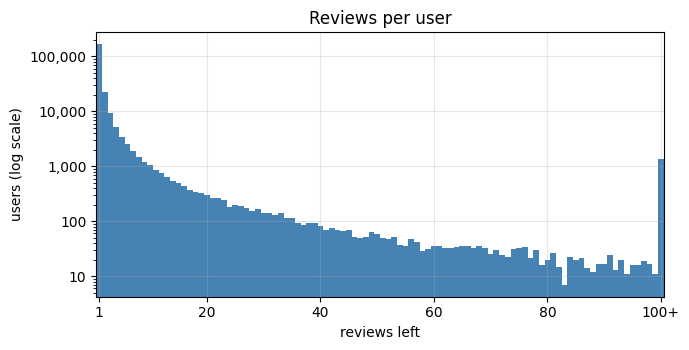

users 226,570 | median 1 | 90% 5 | 99% 61 | max 7,671
users with 1 review: 166,256 | 2 reviews: 22,738 | 3 reviews: 9,346
users with 100+ reviews (last bar): 1,382 | 1,000+: 96


,users,% of users,% of all reviews
reviews left,,,
1,166256,73.4,14.7
2-4,37228,16.4,8.3
5-9,10600,4.7,6.1
10-49,9731,4.3,17.4
50-99,1373,0.6,8.4
100+,1382,0.6,45.2


In [3]:
uc = inter.groupby("user_id").size().to_numpy()   # reviews per user

CAP = 100
counts = np.bincount(np.minimum(uc, CAP))         # bar 100 = users with 100+ reviews
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.bar(np.arange(1, CAP + 1), counts[1:], width=1, color="steelblue")
ax.set_xlim(0.5, CAP + 0.5)
ax.set_xticks([1, 20, 40, 60, 80, CAP], ["1", "20", "40", "60", "80", f"{CAP}+"])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_title("Reviews per user"); ax.set_xlabel("reviews left"); ax.set_ylabel("users (log scale)")
plt.tight_layout(); plt.show()

p50, p90, p99 = np.percentile(uc, [50, 90, 99])
print(f"users {len(uc):,} | median {p50:.0f} | 90% {p90:.0f} | 99% {p99:.0f} | max {uc.max():,}")
print(f"users with 1 review: {counts[1]:,} | 2 reviews: {counts[2]:,} | 3 reviews: {counts[3]:,}")
print(f"users with 100+ reviews (last bar): {(uc >= CAP).sum():,} | 1,000+: {(uc >= 1000).sum():,}")

edges = [1, 2, 5, 10, 50, 100, np.inf]
labels = ["1", "2-4", "5-9", "10-49", "50-99", "100+"]
grp = np.digitize(uc, edges) - 1
pd.DataFrame({"users": np.bincount(grp, minlength=6),
              "% of users": np.bincount(grp, minlength=6) / len(uc) * 100,
              "% of all reviews": np.bincount(grp, weights=uc, minlength=6) / uc.sum() * 100},
             index=pd.Index(labels, name="reviews left")).round(1)

## Filtering the raw data
Rules we decided on from the graphs above, applied in this order:
1. **Drop rating 0.** A 0 means the review has no stars (a missing rating, not a bad one).
2. **Recipe rules:** keep recipes with **3-40 steps**, **3-18 ingredients** and a cooking time of **5 minutes to 1 day** (1,440 minutes). All bounds are inclusive.
3. **User rule:** keep users with **at least 4 reviews**, counted *after* steps 1-2, so every kept user has 4+ star-rated reviews in the final data.

Output: `dataset/filtered_interactions.csv`, same columns as `RAW_interactions.csv` (`user_id, recipe_id, date, rating, review`). Recipe details can be joined from `RAW_recipes.csv` on `recipe_id = id`; every recipe in the file passes the recipe rules.

In [4]:
MIN_STEPS, MAX_STEPS = 3, 40
MIN_INGR, MAX_INGR = 3, 18
MIN_MINUTES, MAX_MINUTES = 5, 1440      # 5 minutes to 1 day
MIN_USER_REVIEWS = 4

steps = [("raw", inter)]

# 1. drop rating 0 (no stars given)
df = inter[inter.rating > 0]
steps.append(("drop rating 0", df))

# 2. recipe rules
ok = recipes[recipes.n_steps.between(MIN_STEPS, MAX_STEPS)
             & recipes.n_ingredients.between(MIN_INGR, MAX_INGR)
             & recipes.minutes.between(MIN_MINUTES, MAX_MINUTES)]
df = df[df.recipe_id.isin(ok.id)]
steps.append(("recipe rules", df))

# 3. users with >= 4 reviews (counted on what's left)
n_user = df.groupby("user_id").user_id.transform("size")
df = df[n_user >= MIN_USER_REVIEWS]
steps.append(("users with 4+ reviews", df))

filtered = df.reset_index(drop=True)
filtered.to_csv(DATA_PATH + "filtered_interactions.csv", index=False)

print(f"recipes passing recipe rules: {len(ok):,} of {len(recipes):,} ({len(ok) / len(recipes):.1%})")
pd.DataFrame({"reviews": [len(d) for _, d in steps],
              "users": [d.user_id.nunique() for _, d in steps],
              "recipes": [d.recipe_id.nunique() for _, d in steps],
              "% of raw reviews": [len(d) / len(inter) * 100 for _, d in steps]},
             index=pd.Index([n for n, _ in steps], name="after step")).round(1)

recipes passing recipe rules: 210,966 of 231,637 (91.1%)


,reviews,users,recipes,% of raw reviews
after step,,,,
raw,1132367,226570,231637,100.0
drop rating 0,1071520,196098,226590,94.6
recipe rules,984418,185337,206419,86.9
users with 4+ reviews,789268,25533,190323,69.7


In [5]:
# sanity checks on the saved file
chk = pd.read_csv(DATA_PATH + "filtered_interactions.csv")
rec = recipes.set_index("id").loc[chk.recipe_id.unique()]
assert (chk.rating > 0).all()
assert rec.n_steps.between(MIN_STEPS, MAX_STEPS).all() and rec.n_ingredients.between(MIN_INGR, MAX_INGR).all()
assert rec.minutes.between(MIN_MINUTES, MAX_MINUTES).all()
assert chk.groupby("user_id").size().min() >= MIN_USER_REVIEWS
print(f"saved {len(chk):,} rows to {DATA_PATH}filtered_interactions.csv | all checks passed")
print("rating shares: " + " | ".join(f"{r}: {s:.1%}" for r, s in chk.rating.value_counts(normalize=True).sort_index().items()))
print(f"reviews per user: min {chk.groupby('user_id').size().min()} | median {chk.groupby('user_id').size().median():.0f} | max {chk.groupby('user_id').size().max():,}")
print(f"reviews per recipe: min {chk.groupby('recipe_id').size().min()} | median {chk.groupby('recipe_id').size().median():.0f} | max {chk.groupby('recipe_id').size().max():,}")
chk.head()

saved 789,268 rows to ../dataset/filtered_interactions.csv | all checks passed
rating shares: 1: 0.6% | 2: 1.1% | 3: 3.8% | 4: 18.4% | 5: 76.1%
reviews per user: min 4 | median 8 | max 6,935
reviews per recipe: min 1 | median 2 | max 1,074


,user_id,recipe_id,date,rating,review
0,38094,40893,2003-02-17,4,Great with a salad. Cooked on top of stove for...
1,1293707,40893,2011-12-21,5,"So simple, so delicious! Great for chilly fall..."
2,8937,44394,2002-12-01,4,This worked very well and is EASY. I used not...
3,126440,85009,2010-02-27,5,I made the Mexican topping and took it to bunk...
4,57222,85009,2011-10-01,5,"Made the cheddar bacon topping, adding a sprin..."


### Filtered recipes
`dataset/filtered_recipes.csv`: every recipe that has at least one review in `filtered_interactions.csv`, with **all 12 columns** of `RAW_recipes.csv`. These recipes all pass the recipe rules, and every review in the filtered data has its recipe here, so the two files match exactly. (Recipes that pass the rules but lost all their reviews to the user rule are left out, since no model would ever see them.)

In [6]:
filtered_recipes = recipes[recipes.id.isin(filtered.recipe_id)].reset_index(drop=True)
filtered_recipes.to_csv(DATA_PATH + "filtered_recipes.csv", index=False)

chk_r = pd.read_csv(DATA_PATH + "filtered_recipes.csv")
assert list(chk_r.columns) == list(recipes.columns)
assert set(chk_r.id) == set(filtered.recipe_id)
assert chk_r.n_steps.between(MIN_STEPS, MAX_STEPS).all() and chk_r.n_ingredients.between(MIN_INGR, MAX_INGR).all()
assert chk_r.minutes.between(MIN_MINUTES, MAX_MINUTES).all()
print(f"saved {len(chk_r):,} recipes x {chk_r.shape[1]} columns to {DATA_PATH}filtered_recipes.csv | all checks passed")
print(f"passed recipe rules: {len(ok):,} | with >= 1 review after user rule (saved): {len(chk_r):,} | "
      f"left out (no reviews left): {len(ok) - len(chk_r):,}")
chk_r.head(3)

saved 190,323 recipes x 12 columns to ../dataset/filtered_recipes.csv | all checks passed
passed recipe rules: 210,966 | with >= 1 review after user rule (saved): 190,323 | left out (no reviews left): 20,643


,name,id,minutes,contributor_id,submitted,tags,nutrition,n_steps,steps,description,ingredients,n_ingredients
0,arriba baked winter squash mexican style,137739,55,47892,2005-09-16,"['60-minutes-or-less', 'time-to-make', 'course...","[51.5, 0.0, 13.0, 0.0, 2.0, 0.0, 4.0]",11,"['make a choice and proceed with recipe', 'dep...",autumn is my favorite time of year to cook! th...,"['winter squash', 'mexican seasoning', 'mixed ...",7
1,a bit different breakfast pizza,31490,30,26278,2002-06-17,"['30-minutes-or-less', 'time-to-make', 'course...","[173.4, 18.0, 0.0, 17.0, 22.0, 35.0, 1.0]",9,"['preheat oven to 425 degrees f', 'press dough...",this recipe calls for the crust to be prebaked...,"['prepared pizza crust', 'sausage patty', 'egg...",6
2,alouette potatoes,59389,45,68585,2003-04-14,"['60-minutes-or-less', 'time-to-make', 'course...","[368.1, 17.0, 10.0, 2.0, 14.0, 8.0, 20.0]",11,['place potatoes in a large pot of lightly sal...,"this is a super easy, great tasting, make ahea...","['spreadable cheese with garlic and herbs', 'n...",11


## Train / validation / test split (80 / 10 / 10)
Same method as the `workbook.ipynb` template: shuffle all filtered reviews with a fixed seed, then take the first 80% as train, the next 10% as validation and the last 10% as test. The seed makes the split identical every time it's re-run.

Saved as `dataset/filtered_train.csv`, `dataset/filtered_validation.csv` and `dataset/filtered_test.csv` (same columns as `filtered_interactions.csv`).

The table also shows **cold start**: the share of validation/test reviews whose user or recipe never appears in train. A model has nothing learned about those, so it needs a fallback (e.g. the global mean).

In [7]:
SEED = 0
shuffled = filtered.sample(frac=1, random_state=SEED).reset_index(drop=True)
n = len(shuffled)
train = shuffled[:int(0.8 * n)]
valid = shuffled[int(0.8 * n):int(0.9 * n)]
test  = shuffled[int(0.9 * n):]

for name, d in [("train", train), ("validation", valid), ("test", test)]:
    d.to_csv(DATA_PATH + f"filtered_{name}.csv", index=False)

assert len(train) + len(valid) + len(test) == n
known_u, known_i = set(train.user_id), set(train.recipe_id)
pd.DataFrame({
    "reviews": [len(d) for d in (train, valid, test)],
    "% of filtered": [len(d) / n * 100 for d in (train, valid, test)],
    "users": [d.user_id.nunique() for d in (train, valid, test)],
    "recipes": [d.recipe_id.nunique() for d in (train, valid, test)],
    "mean rating": [d.rating.mean() for d in (train, valid, test)],
    "% cold-start users": [0.0] + [(~d.user_id.isin(known_u)).mean() * 100 for d in (valid, test)],
    "% cold-start recipes": [0.0] + [(~d.recipe_id.isin(known_i)).mean() * 100 for d in (valid, test)],
}, index=["train", "validation", "test"]).round(2)

,reviews,% of filtered,users,recipes,mean rating,% cold-start users,% cold-start recipes
train,631414,80.0,25527,171941,4.68,0.00,0.00
validation,78927,10.0,16065,48373,4.68,0.01,12.87
test,78927,10.0,16076,48091,4.69,0.02,12.70
